In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver
import os

In [2]:
#API key
load_dotenv()

api_key = os.getenv("GOOGLE_API_KEY")

print("Key loaded:", bool(api_key))

Key loaded: True


In [3]:
llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")#choose the model you prefer but remember to change langgraph import

In [4]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [ ]:
# "messages" need to be initialize
def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}

In [ ]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

# add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)


chatbot = graph.compile(checkpointer=checkpoint)

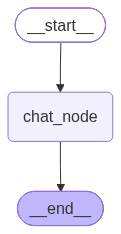

In [7]:
chatbot

In [8]:
thread_id = "2"
initial_state = {
    'messages': [HumanMessage(content='What is my name?')]
}

config = {'configurable': {'thread_id': thread_id}}
response = chatbot.invoke(initial_state, config=config)

In [9]:
response['messages'][-1].content

[{'type': 'text',
  'text': "I don’t know your name. As an AI, I don’t have access to your personal identity, private documents, or webcam unless you have previously shared that information with me in this specific conversation. \n\nIf you have told me your name earlier in this chat, please remind me! Otherwise, I am happy to learn it if you'd like to share.",
  'extras': {'signature': 'EnMKcQFpFH0TrmEIWw+lXm1GKfpH8U9Y9ilg782HrAT9L9XmzHBALEyDfpjfyf75JOfaDKSWg+ca2ayV8uD/MBnvz9P44GoDxezaSWuW3wtx6L66nTlveY5uqdnGd2z1+HfOxG4IHDqFdXj6xGaqi6yrDxqB'}}]

In [10]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='e1bba6d0-af0a-4026-b22d-e66a8b9c8af1'), AIMessage(content=[{'type': 'text', 'text': "I don’t know your name. As an AI, I don’t have access to your personal identity, private documents, or webcam unless you have previously shared that information with me in this specific conversation. \n\nIf you have told me your name earlier in this chat, please remind me! Otherwise, I am happy to learn it if you'd like to share.", 'extras': {'signature': 'EnMKcQFpFH0TrmEIWw+lXm1GKfpH8U9Y9ilg782HrAT9L9XmzHBALEyDfpjfyf75JOfaDKSWg+ca2ayV8uD/MBnvz9P44GoDxezaSWuW3wtx6L66nTlveY5uqdnGd2z1+HfOxG4IHDqFdXj6xGaqi6yrDxqB'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1cee5-1f16-72ce-aa25-4bd95bbffe73-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'

In [11]:
# thread_id 是 LangGraph 用來識別不同對話內容盒子得概念
thread_id = "1"

while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

Type here:  I am Zachary


User: I am Zachary
AI: [{'type': 'text', 'text': 'Hello, Zachary! It’s nice to meet you. How is your day going so far? Is there anything I can help you with?', 'extras': {'signature': 'EnMKcQFpFH0Tb/z6uupbk8Gy8+PrUqkiIhc7Jk3IizZUGWfDCYRnguTjcAOHveIqFaoiDFWV90E0KBeW372J6gZ8R2xltgFLfeylShEwWUk+UetMBn59FOJ4DHMnT4Nfm6/+Dk9CN6X5T8whqPGOIm0hw0r7'}}]


Type here:  what is my name


User: what is my name
AI: [{'type': 'text', 'text': 'Your name is Zachary.', 'extras': {'signature': 'EnMKcQFpFH0TWXk7/UCTilwSH3J49a01hNhiGJ0qTUd10n7Q9CECTsd/LY+uDWq2/olt/dYxX23DRkT9pNtfN/WmRWHAMHvgq09RlqMfCTwtJ3tfn/dKwZY6ZoE5JymGKQREh2wEniaoMfywI+R0ltoX64Z3'}}]


Type here:  exit


User: exit
